# Maya — Final ISSP 1–7 baseline, drivers, and Keras comparison

In [43]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)
from sklearn.inspection import permutation_importance
from sklearn.base import clone
SEED=42
pd.set_option('display.max_columns',100)


## 1. Load the team's merged ISSP–O*NET CSV
The original corrected notebook expects `data/constructed_datasets/issp_onet_baseline_us.csv`. In Colab, run the cell and upload that **merged CSV** when prompted. Do not upload an unrelated raw ISSP file; the expected columns must include `job_satisfaction`.

In [33]:
DATA_FILE = 'data/constructed_datasets/issp_onet_baseline_us.csv'
possible = [Path(DATA_FILE), Path('issp_onet_baseline_us.csv'), Path('/mnt/data/issp_onet_baseline_us.csv')]
possible += [p / DATA_FILE for p in Path.cwd().resolve().parents]
path = next((p for p in possible if p.is_file()), None)
if path is None:
    try:
        from google.colab import files
        print('Upload the merged file: issp_onet_baseline_us.csv')
        uploaded = files.upload()
        if not uploaded: raise RuntimeError('No CSV uploaded')
        from io import BytesIO
        df = pd.read_csv(BytesIO(next(iter(uploaded.values()))), dtype={'ONET_SOC_CODE':'string'})
    except ImportError:
        path = Path(input('Enter full path to merged ISSP–O*NET CSV: ').strip().strip('"'))
        if not path.is_file(): raise FileNotFoundError(path)
        df = pd.read_csv(path, dtype={'ONET_SOC_CODE':'string'})
else:
    print('Loaded:',path)
    df = pd.read_csv(path, dtype={'ONET_SOC_CODE':'string'})
print('Dataset shape:',df.shape)
print('Columns:',df.columns.tolist())
display(df.head(3))


Upload the merged file: issp_onet_baseline_us.csv


Saving issp_onet_baseline_us (3).csv to issp_onet_baseline_us (3) (2).csv
Dataset shape: (2040, 44)
Columns: ['ONET_SOC_CODE', 'module_year', 'job_satisfaction', 'age', 'sex', 'marital_status', 'educ_years', 'educ_level', 'household_income_group', 'hours_worked_weekly', 'employment_status_current', 'union_member', 'household_size', 'child_in_household', 'urban_rural', 'imp_job_security', 'imp_income', 'imp_advancement', 'imp_interesting', 'imp_independence', 'imp_help_others', 'imp_useful_society', 'imp_decide_hours', 'actual_job_secure', 'actual_income_high', 'actual_advancement_high', 'actual_job_interesting', 'actual_work_independently', 'actual_help_others', 'actual_useful_society', 'onet_job_zone', 'career_interest_types_OI_artistic_value', 'career_interest_types_OI_conventional_value', 'career_interest_types_OI_enterprising_value', 'career_interest_types_OI_investigative_value', 'career_interest_types_OI_realistic_value', 'career_interest_types_OI_social_value', 'fit_gap_security

,ONET_SOC_CODE,module_year,job_satisfaction,age,sex,marital_status,educ_years,educ_level,household_income_group,hours_worked_weekly,employment_status_current,union_member,household_size,child_in_household,urban_rural,imp_job_security,imp_income,imp_advancement,imp_interesting,imp_independence,imp_help_others,imp_useful_society,imp_decide_hours,actual_job_secure,actual_income_high,actual_advancement_high,actual_job_interesting,actual_work_independently,actual_help_others,actual_useful_society,onet_job_zone,career_interest_types_OI_artistic_value,career_interest_types_OI_conventional_value,career_interest_types_OI_enterprising_value,career_interest_types_OI_investigative_value,career_interest_types_OI_realistic_value,career_interest_types_OI_social_value,fit_gap_security,fit_gap_income,fit_gap_advancement,fit_gap_interesting,fit_gap_independence,fit_gap_help_others,fit_gap_useful_society
0,25-2056.00,1997.0,5.0,33.0,1.0,3.0,16.0,4.0,2.0,40.0,1.0,3.0,2.0,1.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,3.0,2.0,4.0,4.0,2.0,2.0,1.0,1.0,4.0,3.65,3.48,1.77,3.94,2.27,7.00,-1.0,-3.0,-2.0,0.0,0.0,1.0,1.0
1,45-2011.00,1997.0,3.0,43.0,1.0,4.0,12.0,3.0,3.0,40.0,1.0,3.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,3.0,2.0,3.0,3.0,2.0,2.0,2.0,2.0,2.0,1.00,5.17,3.12,4.04,5.35,1.89,0.0,-1.0,-1.0,-1.0,0.0,0.0,0.0
2,17-2071.00,1997.0,4.0,45.0,1.0,3.0,15.0,4.0,3.0,50.0,1.0,3.0,1.0,2.0,1.0,2.0,2.0,3.0,2.0,3.0,2.0,2.0,3.0,3.0,3.0,4.0,4.0,3.0,4.0,3.0,4.0,2.12,4.43,2.44,5.45,6.02,1.72,-1.0,-1.0,-1.0,-2.0,0.0,-2.0,-1.0


## 2. Verify the 1–7 target and examine imbalance
Keep valid integer scores 1–7; do not turn scores into satisfied/neutral/dissatisfied groups. The previous **85%** statistic referred to the old grouped target and is **not** the majority-class rate for the new seven-class problem.

Excluded missing/invalid target rows: 0


,n,percent
job_satisfaction,,
1,356,17.45
2,712,34.90
3,662,32.45
4,135,6.62
5,110,5.39
6,49,2.40
7,16,0.78


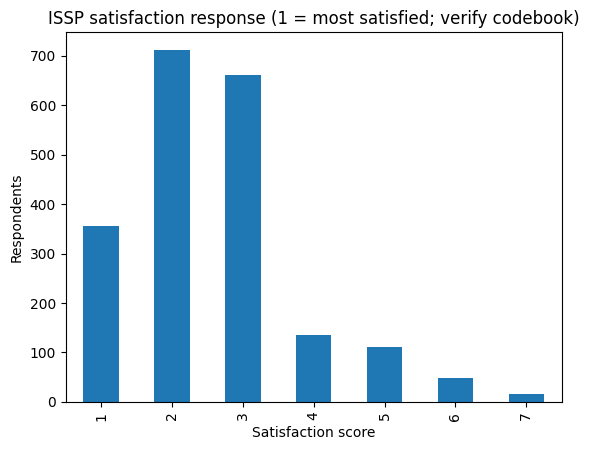

Seven-class majority prediction accuracy: 0.349


In [34]:
TARGET='job_satisfaction'
if TARGET not in df: raise KeyError(f'Missing {TARGET}: check uploaded CSV')
raw=pd.to_numeric(df[TARGET],errors='coerce')
valid=raw.isin(range(1,8))
print('Excluded missing/invalid target rows:',(~valid).sum())
df=df.loc[valid].copy()
df[TARGET]=raw.loc[valid].astype(int)
counts=df[TARGET].value_counts().reindex(range(1,8),fill_value=0)
display(pd.DataFrame({'n':counts,'percent':(100*counts/len(df)).round(2)}))
counts.plot.bar(title='ISSP satisfaction response (1 = most satisfied; verify codebook)')
plt.xlabel('Satisfaction score');plt.ylabel('Respondents');plt.show()
print('Seven-class majority prediction accuracy:',round(counts.max()/counts.sum(),4))
if (counts==0).any(): print('WARNING: some classes absent; seven-class AUC/stratification may be unavailable.')


## 3. Select baseline features and prevent leakage
The old baseline included almost every numeric column. That can accidentally include survey answers measuring satisfaction or the job-preference/fit inputs being tested later. This version uses an **explicit, editable baseline feature list**. Review it against the codebook. The listed variables must be measured independently of the outcome. Country is unavailable for comparisons if this is the U.S.-only file.

In [35]:
BASELINE_CANDIDATES = [
    'age','sex','gender','race','race_ethnicity','ethnicity','educ_level','education',
    'marital_status','household_income_group','employment_status_current',
    'union_member','urban_rural','module_year','survey_year','country',
    'ONET_SOC_CODE', # occupation identifier (high-cardinality; use with care)
]
# Remove any candidate you cannot justify from the source codebook.
base_cols=[c for c in BASELINE_CANDIDATES if c in df.columns]
print('Selected baseline columns:',base_cols)
print('Available columns not included (review for legitimate baseline covariates):')
print([c for c in df.columns if c not in base_cols+[TARGET]][:100])
if not base_cols: raise ValueError('No matching baseline predictors; update BASELINE_CANDIDATES using the printed columns')
# Important: never include satisfaction proxies, fit gaps, IDs or post-outcome measurements in baseline.
assert TARGET not in base_cols
for col in base_cols:
    print(col, 'missing',round(df[col].isna().mean()*100,1),'%', 'unique',df[col].nunique(dropna=True))


Selected baseline columns: ['age', 'sex', 'educ_level', 'marital_status', 'household_income_group', 'employment_status_current', 'union_member', 'urban_rural', 'module_year', 'ONET_SOC_CODE']
Available columns not included (review for legitimate baseline covariates):
['educ_years', 'hours_worked_weekly', 'household_size', 'child_in_household', 'imp_job_security', 'imp_income', 'imp_advancement', 'imp_interesting', 'imp_independence', 'imp_help_others', 'imp_useful_society', 'imp_decide_hours', 'actual_job_secure', 'actual_income_high', 'actual_advancement_high', 'actual_job_interesting', 'actual_work_independently', 'actual_help_others', 'actual_useful_society', 'onet_job_zone', 'career_interest_types_OI_artistic_value', 'career_interest_types_OI_conventional_value', 'career_interest_types_OI_enterprising_value', 'career_interest_types_OI_investigative_value', 'career_interest_types_OI_realistic_value', 'career_interest_types_OI_social_value', 'fit_gap_security', 'fit_gap_income', 'fit

## 4. Common held-out split and preprocessing
Same split for every algorithm. Categorical-coded columns are explicitly selected. High-cardinality occupation codes may be useful but can make models sparse; compare results with/without them if needed.

In [36]:
CATEGORICAL_CANDIDATES = {'sex','gender','race','race_ethnicity','ethnicity','educ_level',
    'education','marital_status','household_income_group','employment_status_current',
    'union_member','urban_rural','module_year','survey_year','country','ONET_SOC_CODE'}
# For very sparse categories, train/test stratification may fail; do not silently merge labels.
y=df[TARGET]
if y.value_counts().min()<2: raise ValueError('At least one observed satisfaction category has fewer than 2 rows: cannot stratify reliably.')
train_idx,test_idx=train_test_split(df.index,test_size=.25,random_state=SEED,stratify=y)
y_train=y.loc[train_idx];y_test=y.loc[test_idx]
print('Train/test sizes:',len(train_idx),len(test_idx))
def make_pipe(cols,estimator):
    cats=[c for c in cols if c in CATEGORICAL_CANDIDATES or not pd.api.types.is_numeric_dtype(df[c])]
    nums=[c for c in cols if c not in cats]
    parts=[]
    if nums: parts.append(('num',Pipeline([('impute',SimpleImputer(strategy='median')),
                                             ('scale',StandardScaler())]),nums))
    if cats: parts.append(('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                                             ('onehot',OneHotEncoder(handle_unknown='ignore'))]),cats))
    return Pipeline([('prep',ColumnTransformer(parts)),('model',estimator)])
def models():
    return {'Majority dummy':DummyClassifier(strategy='most_frequent'),
            'Weighted logistic':LogisticRegression(max_iter=3000,class_weight='balanced',random_state=SEED),
            'Weighted tree':DecisionTreeClassifier(max_depth=6,min_samples_leaf=10,class_weight='balanced',random_state=SEED),
            'Weighted forest':RandomForestClassifier(n_estimators=250,min_samples_leaf=5,class_weight='balanced',random_state=SEED,n_jobs=-1)}
def score_model(name,features,pipe):
    p=pipe.predict(df.loc[test_idx,features]); classes=pipe.named_steps['model'].classes_
    r={'model':name,'accuracy':accuracy_score(y_test,p),
       'balanced_accuracy':balanced_accuracy_score(y_test,p),
       'macro_f1':f1_score(y_test,p,labels=list(range(1,8)),average='macro',zero_division=0)}
    # OVR AUC needs probability for every one of the 7 classes and presence in held-out data.
    try:
        probs=pipe.predict_proba(df.loc[test_idx,features])
        if set(classes)==set(range(1,8)) and set(y_test.unique())==set(range(1,8)):
            probs=probs[:,[list(classes).index(k) for k in range(1,8)]]
            r['ovr_auc_macro']=roc_auc_score(y_test,probs,labels=list(range(1,8)),multi_class='ovr',average='macro')
        else:r['ovr_auc_macro']=np.nan
    except (ValueError,AttributeError):r['ovr_auc_macro']=np.nan
    return r,p


Train/test sizes: 1530 510


## 5. Train and evaluate seven-class baseline models

In [37]:
baseline_models={};baseline_predictions={};rows=[]
for name,est in models().items():
    pipe=make_pipe(base_cols,est)
    pipe.fit(df.loc[train_idx,base_cols],y_train)
    row,p=score_model(name,base_cols,pipe)
    baseline_models[name]=pipe;baseline_predictions[name]=p
    rows.append(row)
results=pd.DataFrame(rows).set_index('model').sort_values('macro_f1',ascending=False)
display(results.round(4))
for name,p in baseline_predictions.items():
    print('\n',name)
    print(classification_report(y_test,p,labels=list(range(1,8)),zero_division=0))


,accuracy,balanced_accuracy,macro_f1,ovr_auc_macro
model,,,,
Weighted forest,0.2255,0.1832,0.1500,0.5460
Weighted logistic,0.1588,0.1504,0.1168,0.5148
Weighted tree,0.1608,0.2286,0.1127,0.5453
Majority dummy,0.3490,0.1429,0.0739,0.5000



 Majority dummy
              precision    recall  f1-score   support

           1       0.00      0.00      0.00        89
           2       0.35      1.00      0.52       178
           3       0.00      0.00      0.00       166
           4       0.00      0.00      0.00        34
           5       0.00      0.00      0.00        27
           6       0.00      0.00      0.00        12
           7       0.00      0.00      0.00         4

    accuracy                           0.35       510
   macro avg       0.05      0.14      0.07       510
weighted avg       0.12      0.35      0.18       510


 Weighted logistic
              precision    recall  f1-score   support

           1       0.19      0.19      0.19        89
           2       0.41      0.22      0.28       178
           3       0.27      0.10      0.15       166
           4       0.02      0.06      0.03        34
           5       0.06      0.15      0.08        27
           6       0.01      0.08      0.

## 6. Identify influential baseline variables
Permutation importance shows which predictors help the model on held-out data; it does **not** establish causation. Use the highest macro-F1 non-dummy model descriptively. Avoid repeatedly tuning to the test set.

Model for exploratory driver analysis: Weighted forest


,feature,mean_balanced_accuracy_drop,std
1,sex,0.008104,0.025828
0,age,0.005278,0.007474
6,union_member,0.002516,0.013552
5,employment_status_current,-0.002801,0.001719
2,educ_level,-0.007296,0.009280
8,module_year,-0.007353,0.023640
7,urban_rural,-0.012895,0.021565
3,marital_status,-0.013206,0.017577
9,ONET_SOC_CODE,-0.017447,0.006788
4,household_income_group,-0.029788,0.009815


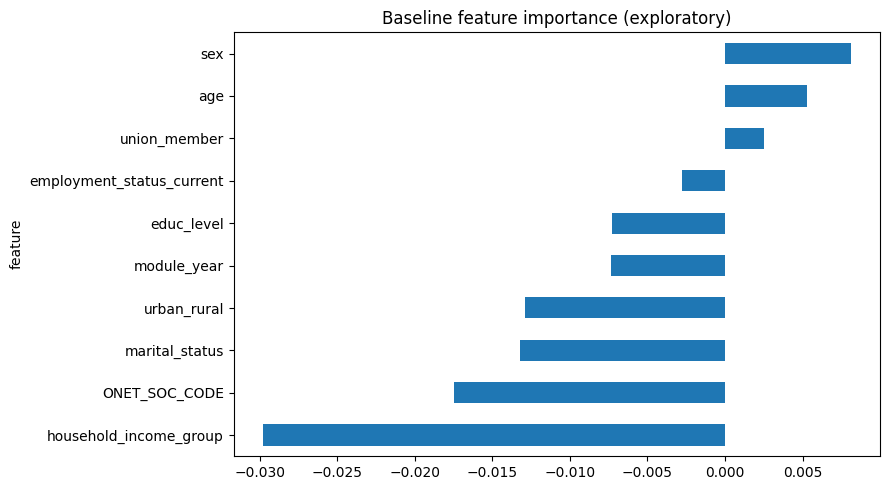

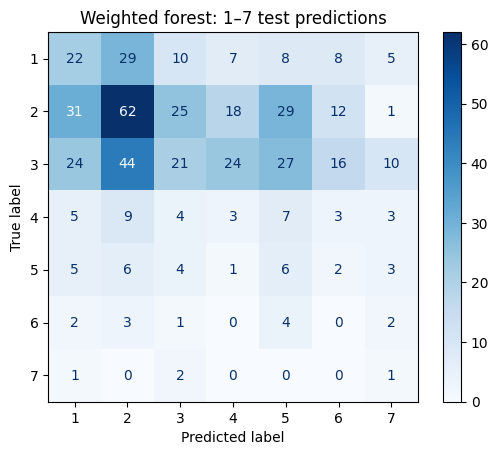

In [38]:
choice=results.drop(index='Majority dummy').macro_f1.idxmax()
chosen=baseline_models[choice]
print('Model for exploratory driver analysis:',choice)
importance=permutation_importance(chosen,df.loc[test_idx,base_cols],y_test,
    scoring='balanced_accuracy',n_repeats=5,random_state=SEED,n_jobs=1)
drivers=pd.DataFrame({'feature':base_cols,'mean_balanced_accuracy_drop':importance.importances_mean,
                      'std':importance.importances_std}).sort_values('mean_balanced_accuracy_drop',ascending=False)
display(drivers)
drivers.head(15).sort_values('mean_balanced_accuracy_drop').plot.barh(
    x='feature',y='mean_balanced_accuracy_drop',legend=False,figsize=(9,5))
plt.title('Baseline feature importance (exploratory)');plt.tight_layout();plt.show()
ConfusionMatrixDisplay.from_predictions(y_test,baseline_predictions[choice],labels=list(range(1,8)),cmap='Blues')
plt.title(f'{choice}: 1–7 test predictions');plt.show()


## 7. Demographic and occupation descriptive comparisons (Task 4)
These are observed associations. Small groups may be noisy. For a U.S.-only dataset, `country` cannot explain cross-country differences.

/tmp/ipykernel_1671/1172007205.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = df[col].astype('object').fillna('Missing')


job_satisfaction,n,score_1,score_2,score_3,score_4,score_5,score_6,score_7
sex,,,,,,,,
2.0,1041,17.2,35.6,32.5,6.2,4.9,2.6,1.0
1.0,999,17.7,34.1,32.4,7.0,5.9,2.2,0.6


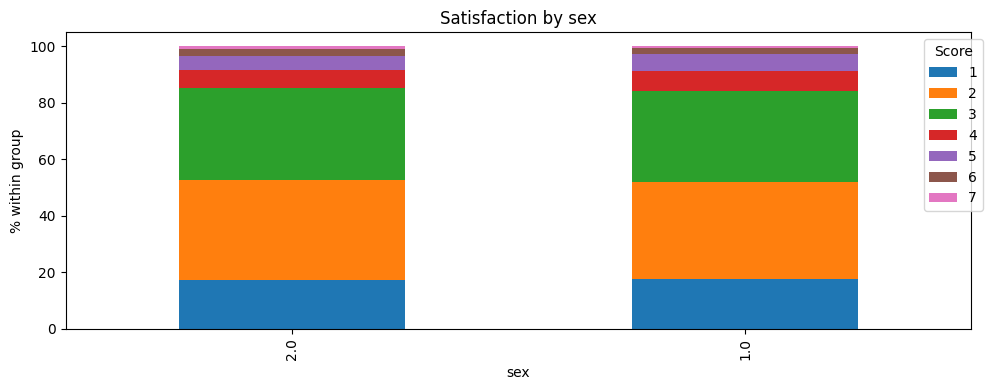

/tmp/ipykernel_1671/1172007205.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = df[col].astype('object').fillna('Missing')


job_satisfaction,n,score_1,score_2,score_3,score_4,score_5,score_6,score_7
educ_level,,,,,,,,
3.0,933,18.3,30.5,35.3,6.8,5.7,2.6,0.9
5.0,529,13.0,43.7,31.0,5.5,4.2,1.7,0.9
4.0,391,15.9,36.8,30.7,7.2,6.1,2.8,0.5
2.0,119,29.4,23.5,27.7,9.2,7.6,2.5,0.0
1.0,49,24.5,36.7,22.4,6.1,4.1,4.1,2.0
0.0,19,36.8,31.6,26.3,5.3,0.0,0.0,0.0


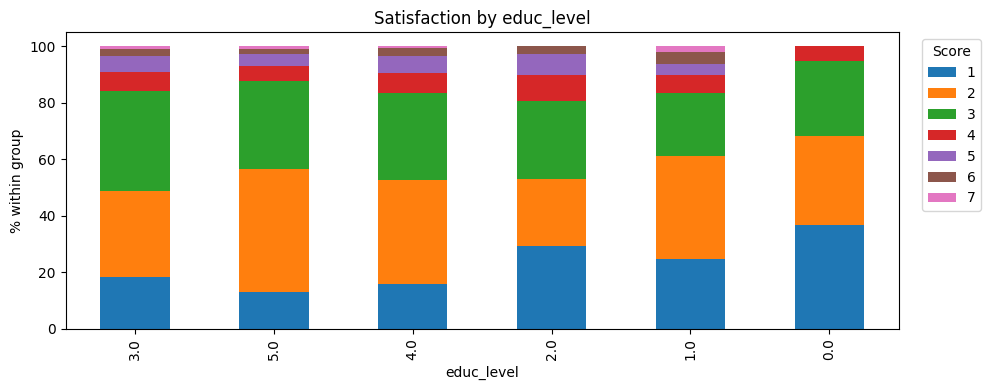

/tmp/ipykernel_1671/1172007205.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = df[col].astype('object').fillna('Missing')


job_satisfaction,n,score_1,score_2,score_3,score_4,score_5,score_6,score_7
module_year,,,,,,,,
2015.0,872,17.7,37.2,30.8,5.7,5.8,2.2,0.6
2005.0,648,19.0,36.3,30.9,6.9,3.1,2.9,0.9
1997.0,520,15.2,29.4,37.1,7.7,7.5,2.1,1.0


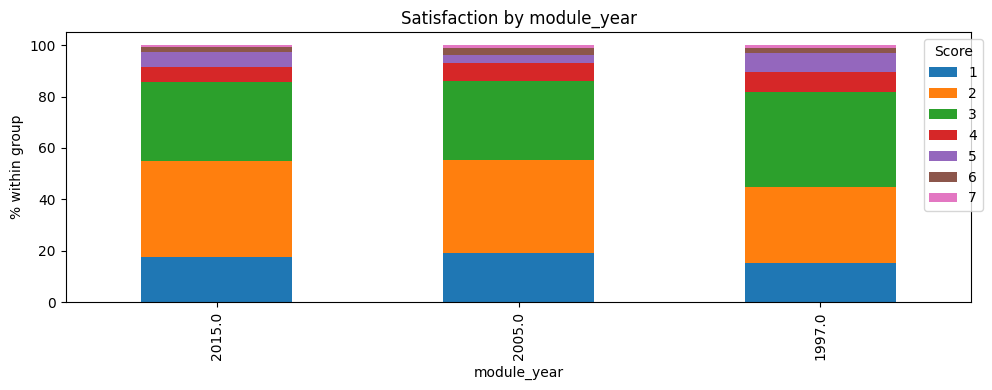

job_satisfaction,n,score_1,score_2,score_3,score_4,score_5,score_6,score_7
ONET_SOC_CODE,,,,,,,,
41-2031.00,71,21.1,19.7,31.0,8.5,7.0,9.9,2.8
11-1021.00,66,18.2,43.9,31.8,4.5,1.5,0.0,0.0
25-2021.00,56,16.1,41.1,26.8,5.4,7.1,0.0,3.6
53-7011.00,54,13.0,20.4,40.7,13.0,5.6,5.6,1.9
53-3032.00,47,19.1,27.7,38.3,2.1,8.5,2.1,2.1
43-6014.00,44,9.1,31.8,43.2,15.9,0.0,0.0,0.0
53-7062.00,43,11.6,16.3,34.9,14.0,14.0,7.0,2.3
41-2011.00,40,7.5,22.5,40.0,12.5,15.0,2.5,0.0
35-2014.00,39,23.1,25.6,30.8,7.7,10.3,2.6,0.0


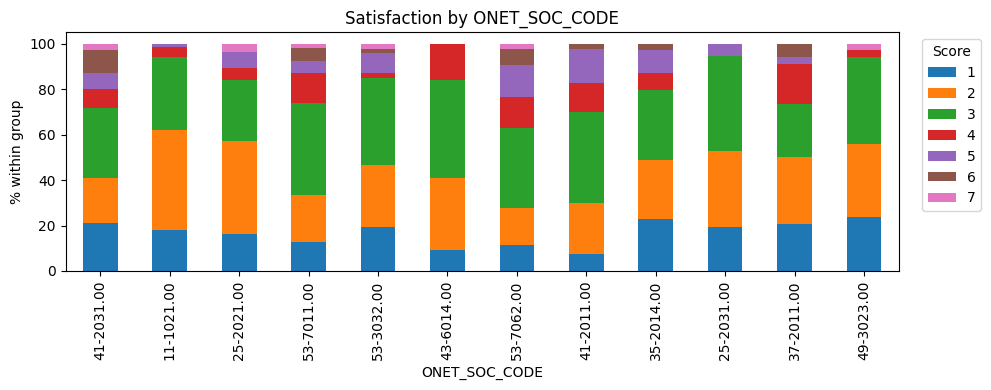

job_satisfaction,n,score_1,score_2,score_3,score_4,score_5,score_6,score_7
age_band,,,,,,,,
36–45,553,16.3,37.6,28.9,6.9,6.7,3.1,0.5
26–35,481,16.6,32.2,35.6,6.9,5.8,2.3,0.6
46–55,443,17.6,31.8,36.6,6.3,3.8,2.5,1.4
56–65,263,20.2,38.4,29.3,4.9,3.8,1.9,1.5
18–25,208,11.5,32.2,36.5,10.1,7.2,2.4,0.0
66+,92,33.7,43.5,17.4,2.2,3.3,0.0,0.0


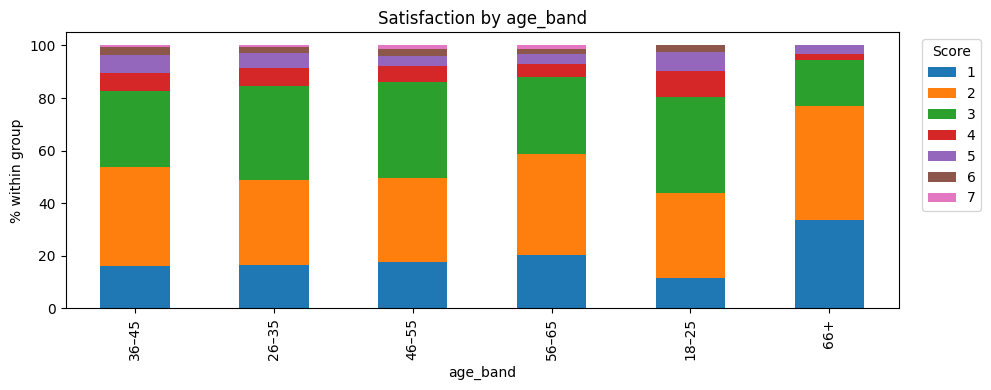

In [39]:

# 7. Demographic and occupation comparisons

def show_group(col, top_n=12):
    if col not in df:
        print(col, ': not present')
        return

    # FIX: convert categorical values to object before fillna
    values = df[col].astype('object').fillna('Missing')

    tab = pd.crosstab(values, df[TARGET])
    tab = tab.reindex(columns=range(1, 8), fill_value=0)

    tab['n'] = tab.sum(axis=1)
    tab = tab.sort_values('n', ascending=False).head(top_n)

    pct = tab[list(range(1, 8))].div(tab['n'], axis=0) * 100

    display(tab[['n']].join(pct.add_prefix('score_')).round(1))

    pct.plot.bar(stacked=True, figsize=(10, 4))
    plt.ylabel('% within group')
    plt.title(f'Satisfaction by {col}')
    plt.legend(title='Score', bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()


for col in [
    'sex', 'gender', 'race', 'race_ethnicity',
    'educ_level', 'module_year', 'survey_year',
    'country', 'ONET_SOC_CODE'
]:
    if col in df:
        show_group(col)

if 'age' in df:
    ages = pd.to_numeric(df['age'], errors='coerce')

    df['age_band'] = pd.cut(
        ages,
        bins=[17, 25, 35, 45, 55, 65, np.inf],
        labels=['18–25', '26–35', '36–45',
                '46–55', '56–65', '66+']
    )

    show_group('age_band')



## 8. ISSP–O*NET preference / occupation fit mapping (Task 8)
**Do not assume that similarly named variables measure the same construct.** Verify ISSP item wording and coding, O*NET element ID, scale and year. The template below is intentionally not a completed mapping. Normalize both scales to a common meaningful direction before computing gaps; don't assume an occupation-level score is an individual worker's actual experience.

In [40]:
mapping=pd.DataFrame([
    {'ISSP_preference_column':'VERIFY security importance item','ONET_occupation_column':'VERIFY job-security proxy','direction_and_scale':'VERIFY','approved':False},
    {'ISSP_preference_column':'VERIFY autonomy importance item','ONET_occupation_column':'VERIFY autonomy measure','direction_and_scale':'VERIFY','approved':False},
    {'ISSP_preference_column':'VERIFY interesting work item','ONET_occupation_column':'VERIFY matching work characteristic','direction_and_scale':'VERIFY','approved':False},
])
display(mapping)
print('Available columns potentially relevant to fit:')
print([c for c in df if any(t in c.lower() for t in ['secure','autonom','independ','interest','advance','work_style','work_context','fit_gap'])])


,ISSP_preference_column,ONET_occupation_column,direction_and_scale,approved
0,VERIFY security importance item,VERIFY job-security proxy,VERIFY,False
1,VERIFY autonomy importance item,VERIFY autonomy measure,VERIFY,False
2,VERIFY interesting work item,VERIFY matching work characteristic,VERIFY,False


Available columns potentially relevant to fit:
['imp_advancement', 'imp_interesting', 'imp_independence', 'actual_job_secure', 'actual_advancement_high', 'actual_job_interesting', 'actual_work_independently', 'career_interest_types_OI_artistic_value', 'career_interest_types_OI_conventional_value', 'career_interest_types_OI_enterprising_value', 'career_interest_types_OI_investigative_value', 'career_interest_types_OI_realistic_value', 'career_interest_types_OI_social_value', 'fit_gap_security', 'fit_gap_income', 'fit_gap_advancement', 'fit_gap_interesting', 'fit_gap_independence', 'fit_gap_help_others', 'fit_gap_useful_society']


## 9. Fit-model comparison (runs only with **validated** fit gaps)
Add `fit_gap_...` numeric columns to the merged data **after** confirming each mapping and scaling. To avoid leakage, gap calculations should be pre-specified, independent of the satisfaction target, and should not use any statistics learned from the test data. If you derive gap scaling from data, fit that scaling on training folds only. For a fair comparison, use the exact same respondents and test split for both feature sets.

In [44]:
APPROVED_FIT_GAP_COLUMNS = []  # e.g. ['fit_gap_security'] after validation
bad=[c for c in APPROVED_FIT_GAP_COLUMNS if c not in df or not pd.api.types.is_numeric_dtype(df[c])]
if bad: raise ValueError('Missing/non-numeric approved gap columns: '+str(bad))
fit_results=None
if not APPROVED_FIT_GAP_COLUMNS:
    print('Fit model NOT RUN: no validated fit-gap variables provided.')
else:
    fit_cols=base_cols+APPROVED_FIT_GAP_COLUMNS
    compare=[];fit_models={}
    for name,est in models().items():
        if name=='Majority dummy':continue
        for label,cols in [('baseline',base_cols),('baseline + fit',fit_cols)]:
            pipe=make_pipe(cols,clone(est))
            pipe.fit(df.loc[train_idx,cols],y_train)
            metrics,_=score_model(name+' / '+label,cols,pipe)
            metrics.update({'algorithm':name,'features':label})
            compare.append(metrics);fit_models[(name,label)]=pipe
    fit_results=pd.DataFrame(compare)
    display(fit_results.sort_values(['algorithm','features']).round(4))
    pivot=fit_results.pivot(index='algorithm',columns='features',values='macro_f1')
    display((pivot['baseline + fit']-pivot['baseline']).rename('macro_F1_gain'))


Fit model NOT RUN: no validated fit-gap variables provided.


## 10. Optional Keras neural network — baseline and baseline + fit
Run only if TensorFlow is installed. Train two neural networks on the **same** rows/split. Seven output neurons predict classes 1–7 using internal indices 0–6. Class weights are computed **from training data only**. A validation subset is taken from training, not the test set. One-hot encoding is dense here, so large occupation-cardinality datasets can consume significant memory.

In [45]:
RUN_KERAS = True  # change to True to train
if RUN_KERAS:
    import tensorflow as tf
    from sklearn.utils.class_weight import compute_class_weight
    tf.keras.utils.set_random_seed(SEED)
    keras_rows=[]
    sets={'baseline':base_cols}
    if APPROVED_FIT_GAP_COLUMNS: sets['baseline + fit']=base_cols+APPROVED_FIT_GAP_COLUMNS
    for label,cols in sets.items():
        # A fresh validation split from the original training rows.
        subtrain_idx,val_idx=train_test_split(train_idx,test_size=.2,random_state=SEED,stratify=y.loc[train_idx])
        pre=make_pipe(cols,LogisticRegression()).named_steps['prep']
        xtr=pre.fit_transform(df.loc[subtrain_idx,cols]);xval=pre.transform(df.loc[val_idx,cols]);xte=pre.transform(df.loc[test_idx,cols])
        xtr=xtr.toarray() if hasattr(xtr,'toarray') else np.asarray(xtr)
        xval=xval.toarray() if hasattr(xval,'toarray') else np.asarray(xval)
        xte=xte.toarray() if hasattr(xte,'toarray') else np.asarray(xte)
        xtr=xtr.astype('float32');xval=xval.astype('float32');xte=xte.astype('float32')
        yt=(y.loc[subtrain_idx].to_numpy()-1).astype(int)
        yv=(y.loc[val_idx].to_numpy()-1).astype(int)
        weights=compute_class_weight('balanced',classes=np.arange(7),y=yt)
        net=tf.keras.Sequential([tf.keras.layers.Input(shape=(xtr.shape[1],)),
            tf.keras.layers.Dense(64,activation='relu'),tf.keras.layers.Dropout(.25),
            tf.keras.layers.Dense(32,activation='relu'),tf.keras.layers.Dense(7,activation='softmax')])
        net.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
        net.fit(xtr,yt,validation_data=(xval,yv),epochs=60,batch_size=32,verbose=0,
            class_weight={int(i):float(w) for i,w in enumerate(weights)},
            callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=7,restore_best_weights=True)])
        probs=net.predict(xte,verbose=0);pred=probs.argmax(axis=1)+1
        record={'model':'Keras / '+label,'accuracy':accuracy_score(y_test,pred),
            'balanced_accuracy':balanced_accuracy_score(y_test,pred),
            'macro_f1':f1_score(y_test,pred,labels=list(range(1,8)),average='macro',zero_division=0)}
        try:record['ovr_auc_macro']=roc_auc_score(y_test,probs,labels=list(range(1,8)),multi_class='ovr',average='macro')
        except ValueError:record['ovr_auc_macro']=np.nan
        keras_rows.append(record)
        print(label,'\n',classification_report(y_test,pred,labels=list(range(1,8)),zero_division=0))
    display(pd.DataFrame(keras_rows).set_index('model').round(4))
else:
    print('Keras not run. Set RUN_KERAS=True after confirming TensorFlow and data.')


baseline 
               precision    recall  f1-score   support

           1       0.21      0.29      0.25        89
           2       0.43      0.22      0.30       178
           3       0.30      0.20      0.24       166
           4       0.03      0.06      0.04        34
           5       0.07      0.15      0.10        27
           6       0.02      0.08      0.04        12
           7       0.08      0.25      0.12         4

    accuracy                           0.21       510
   macro avg       0.16      0.18      0.15       510
weighted avg       0.29      0.21      0.23       510



,accuracy,balanced_accuracy,macro_f1,ovr_auc_macro
model,,,,
Keras / baseline,0.2118,0.1803,0.1548,0.5368


## 11. Write-up checklist
- Confirm source codebook direction (1 = most satisfied?) and missing-value codes.
- Record class distribution, **seven-class** dummy baseline, macro F1, balanced accuracy, per-class recall, OVR AUC.
- Report which demographic/occupation variables are associated with satisfaction; distinguish correlation from causation.
- Validate each ISSP/O*NET mapping and its scale before generating fit gaps.
- Compare baseline vs fit on the **same test rows**, and Keras baseline vs Keras + fit.
- Explain limitations: class imbalance, sparse occupation groups, U.S.-only sample, occupation-level O*NET proxies, and possible demographic fairness concerns.

**Note:** This notebook is executable code, not completed results. It requires the merged CSV. No fit-model result is claimed until real, validated fit-gap variables exist.

## 12. ISSP–O*NET: Seven-class feature comparison (integrated)

This section is merged into the existing baseline/Keras notebook. **Run Sections 1–4 first** to load the CSV and define `df`, `base_cols`, `train_idx`, `test_idx`, `make_pipe`, `models`, and `score_model`. It uses the **same held-out respondents** and preserves satisfaction classes **1–7**. The `fit_gap_*` variables represent **ISSP preference minus self-reported job experience**, **not validated ISSP–O*NET person–job fit**.

### 12.1 Inventory and audit available variables

In [46]:
# Uses df already loaded in Section 1; do NOT reload or resplit the CSV.
onet_profile_cols = ['onet_job_zone'] + [c for c in df.columns if c.startswith('career_interest_types_OI_')]
issp_gap_cols = [c for c in df.columns if c.startswith('fit_gap_')]
issp_preference_cols = [c for c in df.columns if c.startswith('imp_')]
issp_actual_cols = [c for c in df.columns if c.startswith('actual_')]
print('O*NET occupation profile:', onet_profile_cols)
print('ISSP importance:', issp_preference_cols)
print('ISSP respondent-reported gaps:', issp_gap_cols)
if not onet_profile_cols or not issp_gap_cols:
    raise ValueError('Expected O*NET profile and ISSP gap columns were not found. Check the merged CSV.')
fit_mapping_audit = pd.DataFrame({
    'ISSP construct': ['security','income','advancement','interesting work',
                       'independence','helping others','useful to society'],
    'ISSP preference': ['imp_job_security','imp_income','imp_advancement','imp_interesting',
                        'imp_independence','imp_help_others','imp_useful_society'],
    'ISSP self-reported experience': ['actual_job_secure','actual_income_high',
        'actual_advancement_high','actual_job_interesting','actual_work_independently',
        'actual_help_others','actual_useful_society'],
    'ISSP gap': ['fit_gap_security','fit_gap_income','fit_gap_advancement',
        'fit_gap_interesting','fit_gap_independence','fit_gap_help_others','fit_gap_useful_society'],
    'Validated matching O*NET job characteristic in this CSV': ['Not available'] * 7
})
display(fit_mapping_audit)
for _, r in fit_mapping_audit.iterrows():
    a,b,g = r['ISSP preference'],r['ISSP self-reported experience'],r['ISSP gap']
    if all(c in df.columns for c in (a,b,g)):
        observed = pd.to_numeric(df[a],errors='coerce') - pd.to_numeric(df[b],errors='coerce')
        recorded = pd.to_numeric(df[g],errors='coerce')
        print(g, 'equals importance minus experience:',
              bool(np.isclose(observed, recorded, equal_nan=True).all()))
    else:
        print(g, 'cannot audit: one or more input columns absent')

O*NET occupation profile: ['onet_job_zone', 'career_interest_types_OI_artistic_value', 'career_interest_types_OI_conventional_value', 'career_interest_types_OI_enterprising_value', 'career_interest_types_OI_investigative_value', 'career_interest_types_OI_realistic_value', 'career_interest_types_OI_social_value']
ISSP importance: ['imp_job_security', 'imp_income', 'imp_advancement', 'imp_interesting', 'imp_independence', 'imp_help_others', 'imp_useful_society', 'imp_decide_hours']
ISSP respondent-reported gaps: ['fit_gap_security', 'fit_gap_income', 'fit_gap_advancement', 'fit_gap_interesting', 'fit_gap_independence', 'fit_gap_help_others', 'fit_gap_useful_society']


,ISSP construct,ISSP preference,ISSP self-reported experience,ISSP gap,Validated matching O*NET job characteristic in this CSV
0,security,imp_job_security,actual_job_secure,fit_gap_security,Not available
1,income,imp_income,actual_income_high,fit_gap_income,Not available
2,advancement,imp_advancement,actual_advancement_high,fit_gap_advancement,Not available
3,interesting work,imp_interesting,actual_job_interesting,fit_gap_interesting,Not available
4,independence,imp_independence,actual_work_independently,fit_gap_independence,Not available
5,helping others,imp_help_others,actual_help_others,fit_gap_help_others,Not available
6,useful to society,imp_useful_society,actual_useful_society,fit_gap_useful_society,Not available


fit_gap_security equals importance minus experience: True
fit_gap_income equals importance minus experience: True
fit_gap_advancement equals importance minus experience: True
fit_gap_interesting equals importance minus experience: True
fit_gap_independence equals importance minus experience: True
fit_gap_help_others equals importance minus experience: True
fit_gap_useful_society equals importance minus experience: True


### 12.2 Compare the same models on identical respondents

In [47]:
from sklearn.base import clone
# The existing baseline columns and held-out split are reused exactly.
comparison_feature_sets = {
    'Baseline': list(base_cols),
    'Baseline + O*NET occupation profile': list(dict.fromkeys(list(base_cols) + onet_profile_cols)),
    'Baseline + ISSP respondent gaps': list(dict.fromkeys(list(base_cols) + issp_gap_cols)),
    'Baseline + O*NET + ISSP gaps': list(dict.fromkeys(list(base_cols) + onet_profile_cols + issp_gap_cols))
}
comparison_rows = []
comparison_predictions = {}
for feature_set_name, cols in comparison_feature_sets.items():
    for model_name, estimator in models().items():
        if model_name == 'Majority dummy' and feature_set_name != 'Baseline':
            continue
        model = make_pipe(cols, clone(estimator))
        model.fit(df.loc[train_idx, cols], y_train)
        metrics, preds = score_model(model_name, cols, model)
        comparison_rows.append({'feature_set': feature_set_name, **metrics})
        comparison_predictions[(feature_set_name, model_name)] = preds
feature_comparison_results = pd.DataFrame(comparison_rows)
display(feature_comparison_results[['feature_set','model','accuracy',
                                    'balanced_accuracy','macro_f1','ovr_auc_macro']].round(4))

,feature_set,model,accuracy,balanced_accuracy,macro_f1,ovr_auc_macro
0,Baseline,Majority dummy,0.3490,0.1429,0.0739,0.5000
1,Baseline,Weighted logistic,0.1588,0.1504,0.1168,0.5148
2,Baseline,Weighted tree,0.1608,0.2286,0.1127,0.5453
3,Baseline,Weighted forest,0.2255,0.1832,0.1500,0.5460
4,Baseline + O*NET occupation profile,Weighted logistic,0.1647,0.1502,0.1182,0.5138
5,Baseline + O*NET occupation profile,Weighted tree,0.1412,0.2119,0.1114,0.5463
6,Baseline + O*NET occupation profile,Weighted forest,0.2804,0.2098,0.1772,0.5403
7,Baseline + ISSP respondent gaps,Weighted logistic,0.2471,0.2070,0.1768,0.6365
8,Baseline + ISSP respondent gaps,Weighted tree,0.1941,0.2528,0.1393,0.6030
9,Baseline + ISSP respondent gaps,Weighted forest,0.3373,0.2772,0.2391,0.6976


### 12.3 Improvement in macro F1 over baseline

In [41]:
macro_f1_comparison = feature_comparison_results.query("model != 'Majority dummy'").pivot(
    index='model', columns='feature_set', values='macro_f1'
)
for feature_set_name in comparison_feature_sets:
    if feature_set_name != 'Baseline':
        macro_f1_comparison[feature_set_name + ' — change'] = (
            macro_f1_comparison[feature_set_name] - macro_f1_comparison['Baseline']
        )
display(macro_f1_comparison.round(4))
print('Satisfaction labels:', sorted(y.unique().tolist()))
print('Test sample counts by class:')
display(y_test.value_counts().sort_index())
print('NOTE: O*NET occupation-profile effects are NOT validated ISSP–O*NET fit effects.')

feature_set,Baseline,Baseline + ISSP respondent gaps,Baseline + O*NET + ISSP gaps,Baseline + O*NET occupation profile,Baseline + O*NET occupation profile — change,Baseline + ISSP respondent gaps — change,Baseline + O*NET + ISSP gaps — change
model,,,,,,,
Weighted forest,0.1500,0.2391,0.2402,0.1772,0.0272,0.0891,0.0903
Weighted logistic,0.1168,0.1768,0.1800,0.1182,0.0014,0.0601,0.0633
Weighted tree,0.1127,0.1393,0.1620,0.1114,-0.0013,0.0266,0.0492


Satisfaction labels: [1, 2, 3, 4, 5, 6, 7]
Test sample counts by class:


,count
job_satisfaction,
1,89
2,178
3,166
4,34
5,27
6,12
7,4


NOTE: O*NET occupation-profile effects are NOT validated ISSP–O*NET fit effects.


### 12.4 Plot and save comparison

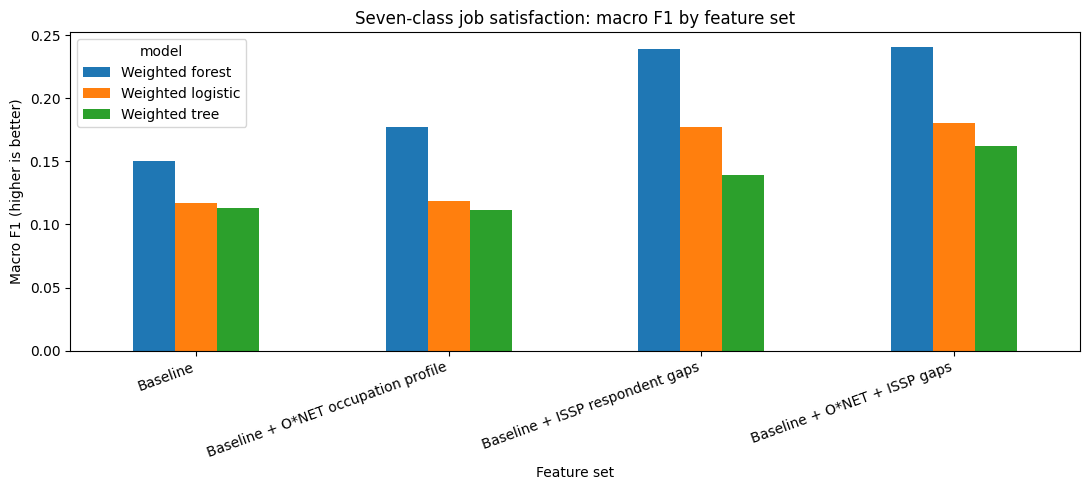

Saved seven_class_feature_comparison_results.csv and issp_onet_fit_mapping_audit.csv


In [48]:
import matplotlib.pyplot as plt
plot_data = feature_comparison_results.query("model != 'Majority dummy'").pivot(
    index='feature_set', columns='model', values='macro_f1'
)
plot_data = plot_data.reindex(list(comparison_feature_sets))
ax = plot_data.plot(kind='bar', figsize=(11,5))
ax.set(title='Seven-class job satisfaction: macro F1 by feature set',
       xlabel='Feature set', ylabel='Macro F1 (higher is better)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()
feature_comparison_results.to_csv('seven_class_feature_comparison_results.csv', index=False)
fit_mapping_audit.to_csv('issp_onet_fit_mapping_audit.csv', index=False)
print('Saved seven_class_feature_comparison_results.csv and issp_onet_fit_mapping_audit.csv')

### 12.5 Interpretation and validation boundary

- **Baseline + O*NET occupation profile** tests whether available occupational descriptors improve prediction.
- **Baseline + ISSP respondent gaps** tests whether survey respondents’ own importance–experience gaps improve prediction.
- **Baseline + O*NET + ISSP gaps** tests the combination.
- **None of these is a validated ISSP–O*NET person–job fit score.** To construct that score, obtain occupation-level O*NET variables measuring the same concepts as ISSP preferences, validate conceptual correspondence and scale direction, then test the resulting features on the held-out split.
- The displayed test results are exploratory; do not tune repeatedly against the held-out test set.

## 13. Results summary and conclusion

### Research question
Does information about occupations and the alignment between a respondent’s job preferences and their reported job experiences help predict **seven-level job satisfaction (1–7)**?

### What was tested
- **Baseline:** demographic and occupation-related predictors from Sections 3–5.
- **Baseline + O*NET profile:** adds available occupation-level O*NET interest ratings and job zone.
- **Baseline + ISSP gaps:** adds respondent-reported differences between job preferences and job experiences.
- **Baseline + both:** includes the O*NET profile and ISSP gaps together.

All comparisons retain **seven classes** and use the same held-out split. **ISSP gaps are not ISSP–O*NET fit scores.**

### Earlier exploratory results (separate run)
The following numbers were reported in the earlier feature-comparison experiment; they are **not** prefilled as results from this combined notebook. Model specifications or preprocessing may differ, so use the live results generated below as the authoritative numbers for this notebook.

| Random Forest feature set | Earlier test macro F1 |
|---|---:|
| Baseline | 0.1499 |
| Baseline + O*NET occupation profile | 0.1742 |
| Baseline + ISSP respondent gaps | 0.2275 |

These results suggest additional job-related features may provide useful predictive information, but performance remains modest. Rare satisfaction classes (especially 6 and 7) limit reliability. Results are **predictive associations, not causal effects**.

### Main conclusion
Occupation descriptors and respondents’ reported preference–experience gaps may help predict job satisfaction, with the reported ISSP-gap comparison showing the larger improvement. **This does not validate an ISSP–O*NET person–job fit score.** A genuine score requires conceptually matched O*NET occupational measures, verified scale direction and harmonization, and separate evaluation. Avoid claiming that the occupation match itself establishes person–job fit.

### Limitations and next steps
The satisfaction outcome is imbalanced, the test set contains few observations in some categories, and feature-set comparisons on a single split are exploratory. Confirm codebook direction and missing-value handling, add validated occupation-level O*NET job characteristics, predefine fit-score construction, and evaluate with cross-validation before drawing stronger conclusions.


### 13.1 Automatically summarize *this notebook’s* actual results



In [42]:
# Live results from Section 12 (same split and preprocessing)
summary = feature_comparison_results.query("model != 'Majority dummy'").copy()
best = summary.loc[summary['macro_f1'].idxmax()]
print('BEST RESULT IN THIS NOTEBOOK')
print(f"{best['model']} | {best['feature_set']} | macro F1 = {best['macro_f1']:.4f}")
print('\nCHANGE FROM BASELINE (MACRO F1)')
for model_name in summary['model'].unique():
    sub = summary[summary['model'] == model_name].set_index('feature_set')
    base = sub.loc['Baseline', 'macro_f1']
    print(f'\n{model_name}: baseline {base:.4f}')
    for name in comparison_feature_sets:
        if name != 'Baseline':
            value = sub.loc[name, 'macro_f1']
            print(f'  {name}: {value:.4f} ({value-base:+.4f})')
print('\nCONCLUSION: These experiments test O*NET occupation-profile features and ISSP respondent gaps,')
print('not a validated cross-source ISSP–O*NET person–job fit score.')


BEST RESULT IN THIS NOTEBOOK
Weighted forest | Baseline + O*NET + ISSP gaps | macro F1 = 0.2402

CHANGE FROM BASELINE (MACRO F1)

Weighted logistic: baseline 0.1168
  Baseline + O*NET occupation profile: 0.1182 (+0.0014)
  Baseline + ISSP respondent gaps: 0.1768 (+0.0601)
  Baseline + O*NET + ISSP gaps: 0.1800 (+0.0633)

Weighted tree: baseline 0.1127
  Baseline + O*NET occupation profile: 0.1114 (-0.0013)
  Baseline + ISSP respondent gaps: 0.1393 (+0.0266)
  Baseline + O*NET + ISSP gaps: 0.1620 (+0.0492)

Weighted forest: baseline 0.1500
  Baseline + O*NET occupation profile: 0.1772 (+0.0272)
  Baseline + ISSP respondent gaps: 0.2391 (+0.0891)
  Baseline + O*NET + ISSP gaps: 0.2402 (+0.0903)

CONCLUSION: These experiments test O*NET occupation-profile features and ISSP respondent gaps,
not a validated cross-source ISSP–O*NET person–job fit score.
